In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_excel('DecodeX_VoltRide_Dataset.xlsx')
df.head(20)

,Ride_ID,City,Date,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By
0,1,Hyderabad,2025-01-01,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,NaN
1,2,Mumbai,2025-01-01,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,NaN
2,3,Delhi,2025-01-01,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,NaN
3,4,Bengaluru,2025-01-01,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System
4,5,Hyderabad,2025-01-01,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,NaN
5,6,Hyderabad,2025-01-01,2,4,10,10.39,728.01,1.2,84,Yes,Yes,Rain,Completed,NaN
6,7,Hyderabad,2025-01-01,23,5,9,21.20,359.73,1.2,98,Yes,Yes,Heavy Rain,Completed,NaN
7,8,Hyderabad,2025-01-01,23,4,1,16.54,300.76,2.0,63,No,Yes,Clear,Cancelled,Driver
8,9,Mumbai,2025-01-01,23,4,9,19.09,313.62,2.0,87,No,No,Clear,Cancelled,Rider
9,10,Delhi,2025-01-01,9,8,6,24.72,572.33,1.2,95,Yes,No,Clear,Completed,NaN


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Ride_ID                  2500 non-null   int64         
 1   City                     2500 non-null   object        
 2   Date                     2500 non-null   datetime64[ns]
 3   Hour                     2500 non-null   int64         
 4   Pickup_Zone              2500 non-null   int64         
 5   Drop_Zone                2500 non-null   int64         
 6   Ride_Distance_km         2500 non-null   float64       
 7   Estimated_Fare           2500 non-null   float64       
 8   Surge_Multiplier         2500 non-null   float64       
 9   EV_Battery_%             2500 non-null   int64         
 10  Driver_Available         2500 non-null   object        
 11  Charging_Station_Nearby  2500 non-null   object        
 12  Weather                  2500 non-

In [ ]:
df["Cancellation_By"]=df["Cancellation_By"].fillna("Not_Cancelled")

In [155]:
df.head()

,City,Date,Day,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By,Cancellation_Flag,Completion_Flag,Low_Battery,Peak_Hour
0,Hyderabad,2025-01-01,Wednesday,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0
1,Mumbai,2025-01-01,Wednesday,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,0
2,Delhi,2025-01-01,Wednesday,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled,0,1,0,0
3,Bengaluru,2025-01-01,Wednesday,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System,1,0,1,0
4,Hyderabad,2025-01-01,Wednesday,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,1


In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Ride_ID                  2500 non-null   int64         
 1   City                     2500 non-null   object        
 2   Date                     2500 non-null   datetime64[ns]
 3   Hour                     2500 non-null   int64         
 4   Pickup_Zone              2500 non-null   int64         
 5   Drop_Zone                2500 non-null   int64         
 6   Ride_Distance_km         2500 non-null   float64       
 7   Estimated_Fare           2500 non-null   float64       
 8   Surge_Multiplier         2500 non-null   float64       
 9   EV_Battery_%             2500 non-null   int64         
 10  Driver_Available         2500 non-null   object        
 11  Charging_Station_Nearby  2500 non-null   object        
 12  Weather                  2500 non-

In [96]:
# Removing Unwanted Columns
df.drop(columns=["Ride_ID"],axis=1,inplace=True)

### Do not Rerun the Above Code ☝️☝️☝️

In [97]:
df.head()

,City,Date,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By
0,Hyderabad,2025-01-01,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled
1,Mumbai,2025-01-01,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled
2,Delhi,2025-01-01,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled
3,Bengaluru,2025-01-01,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System
4,Hyderabad,2025-01-01,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled


In [ ]:
df["Cancellation_Flag"] = (df["Ride_Status"] == "Cancelled").astype(int)
df["Completion_Flag"] = (df["Ride_Status"] == "Completed").astype(int)

df["Low_Battery"] = (df["EV_Battery_%"] < 25).astype(int)
df["Peak_Hour"] = (
    (df["Hour"].between(7,10)) |
    (df["Hour"].between(17,21))
).astype(int)
df.head()


,City,Date,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By,Cancellation_Flag,Completion_Flag,Low_Battery,Peak_Hour
0,Hyderabad,2025-01-01,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0
1,Mumbai,2025-01-01,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,0
2,Delhi,2025-01-01,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled,0,1,0,0
3,Bengaluru,2025-01-01,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System,1,0,1,0
4,Hyderabad,2025-01-01,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,1


In [ ]:
total = len(df)
completed = df["Completion_Flag"].sum()
cancelled = df["Cancellation_Flag"].sum()
print(f"Total Rides: {total}")
print(f"Completion Rate: {(completed/total)*100:.3f}%")
print(f"Cancellation Rate: {(cancelled/total)*100:.3f}%")

Total Rides: 2500
Completion Rate: 70.440%
Cancellation Rate: 29.560%


# Weather vs Surge Analysis

In [159]:
weather_surge = df.groupby("Weather")["Surge_Multiplier"].mean().sort_values(ascending=False)
print("\nAverage Surge Multiplier by Weather Condition:")
print(weather_surge)


Average Surge Multiplier by Weather Condition:
Weather
Heavy Rain    1.459592
Rain          1.422610
Clear         1.415351
Name: Surge_Multiplier, dtype: float64


# Plotting the Weather Vs Surge Analysis

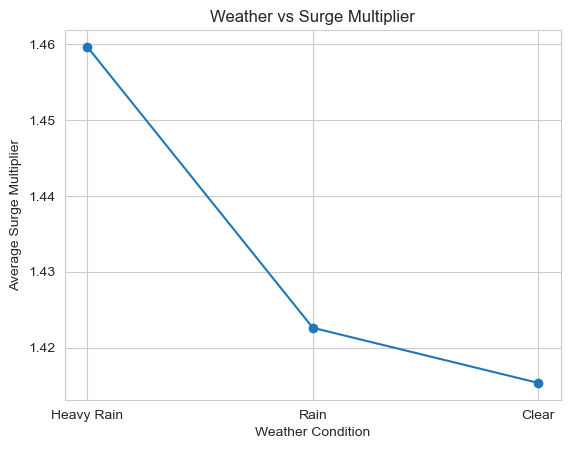

In [166]:
plt.figure()
plt.plot(weather_surge.index, weather_surge.values, marker='o')

plt.title("Weather vs Surge Multiplier")
plt.ylabel("Average Surge Multiplier")
plt.xlabel("Weather Condition")


plt.show()

# Revenue Leakage Analysis

In [ ]:
df["Effective_Fare"] = df["Estimated_Fare"] * df["Surge_Multiplier"]

# Revenue lost due to cancellations
lost_revenue = df[df["Ride_Status"] != "Completed"]["Effective_Fare"].sum()

# Revenue earned
earned_revenue = df[df["Ride_Status"] == "Completed"]["Effective_Fare"].sum()

print("Total Revenue Earned:", round(earned_revenue,2))
print("Total Revenue Lost due to Cancellations:", round(lost_revenue,2))
print("Revenue Leakage %:", round((lost_revenue/(earned_revenue+lost_revenue))*100,2), "%")


Total Revenue Earned: 1134213.3
Total Revenue Lost due to Cancellations: 484627.26
Revenue Leakage %: 29.94 %


# Graph for Revenue Lost

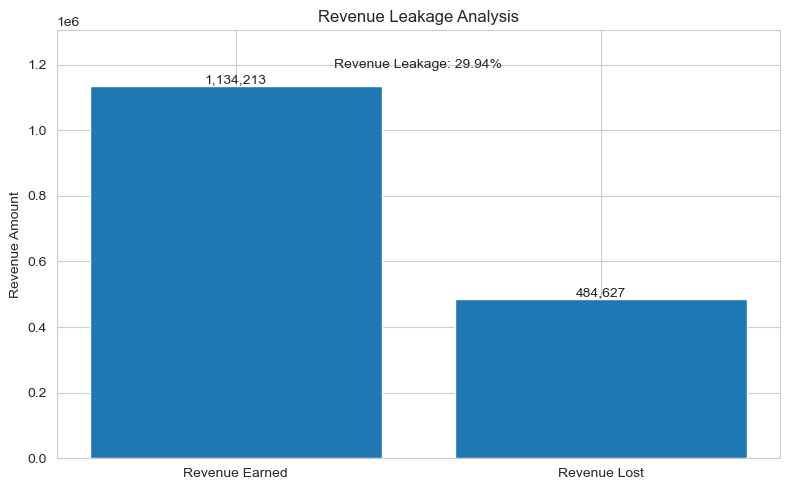

In [ ]:
labels = ["Revenue Earned", "Revenue Lost"]
values = [earned_revenue, lost_revenue]

plt.figure(figsize=(8,5))
bars = plt.bar(labels, values)

plt.title("Revenue Leakage Analysis")
plt.ylabel("Revenue Amount")

for i in range(len(values)):
    plt.text(i, values[i], 
             f"{values[i]:,.0f}", 
             ha='center', va='bottom')
leakage_percent = (lost_revenue / (earned_revenue + lost_revenue)) * 100
plt.text(0.5, max(values)*1.05, 
         f"Revenue Leakage: {leakage_percent:.2f}%", 
         ha='center')

plt.ylim(0, max(values)*1.15)

plt.tight_layout()
plt.show()

# Zone Profitability Ranking

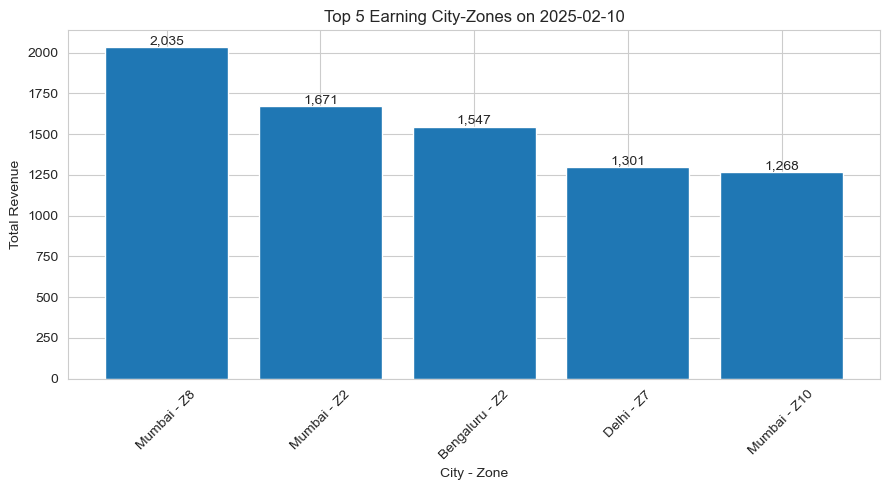

In [ ]:
import matplotlib.pyplot as plt

selected_date = "2025-02-10"   # 🔁 Change this to any date you want


one_day = daily_city_zone[daily_city_zone["Date"] == selected_date]


one_day_sorted = one_day.sort_values("Effective_Fare", ascending=False).head(5)


one_day_sorted["City_Zone"] = one_day_sorted["City"] + " - Z" + one_day_sorted["Pickup_Zone"].astype(str)

plt.figure(figsize=(9,5))
plt.bar(one_day_sorted["City_Zone"], one_day_sorted["Effective_Fare"])

plt.title(f"Top 5 Earning City-Zones on {selected_date}")
plt.xlabel("City - Zone")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

for i in range(len(one_day_sorted)):
    plt.text(i, one_day_sorted["Effective_Fare"].iloc[i],
             f"{one_day_sorted['Effective_Fare'].iloc[i]:,.0f}",
             ha='center', va='bottom')

plt.tight_layout()
plt.show()


# Task-1-> Demand–Supply Stress Mapping Across Cities and Zones

In [100]:
stress = df.groupby(["City","Pickup_Zone","Hour"]).agg(
    Total_Rides=("Ride_Status","count"),
    Cancellation_Rate=("Cancellation_Flag","mean"),
    Avg_Battery=("EV_Battery_%","mean"),
    Avg_Surge=("Surge_Multiplier","mean")
).reset_index()

# Remove very small ride counts (avoid noise)
stress = stress[stress["Total_Rides"] > 5]

# Sort highest risk zone-hours
top_stress = stress.sort_values("Cancellation_Rate", ascending=False).head(15)

top_stress


,City,Pickup_Zone,Hour,Total_Rides,Cancellation_Rate,Avg_Battery,Avg_Surge
669,Mumbai,1,10,6,0.833333,52.166667,1.316667
578,Hyderabad,7,7,8,0.750000,33.375000,1.512500
225,Delhi,1,5,6,0.666667,64.833333,1.750000
70,Bengaluru,4,5,7,0.571429,69.285714,1.600000
758,Mumbai,5,12,6,0.500000,58.000000,1.233333
401,Delhi,9,3,6,0.500000,51.500000,1.366667
408,Delhi,9,13,6,0.500000,47.500000,1.266667
187,Bengaluru,9,11,6,0.500000,64.500000,1.700000
718,Mumbai,3,15,7,0.428571,35.000000,1.442857
680,Mumbai,1,21,7,0.428571,61.714286,1.642857


In [101]:
highest_risk = stress.sort_values("Cancellation_Rate", ascending=False).iloc[0]


C:\Users\TAMILARASU\AppData\Local\Temp\ipykernel_6708\3013172631.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


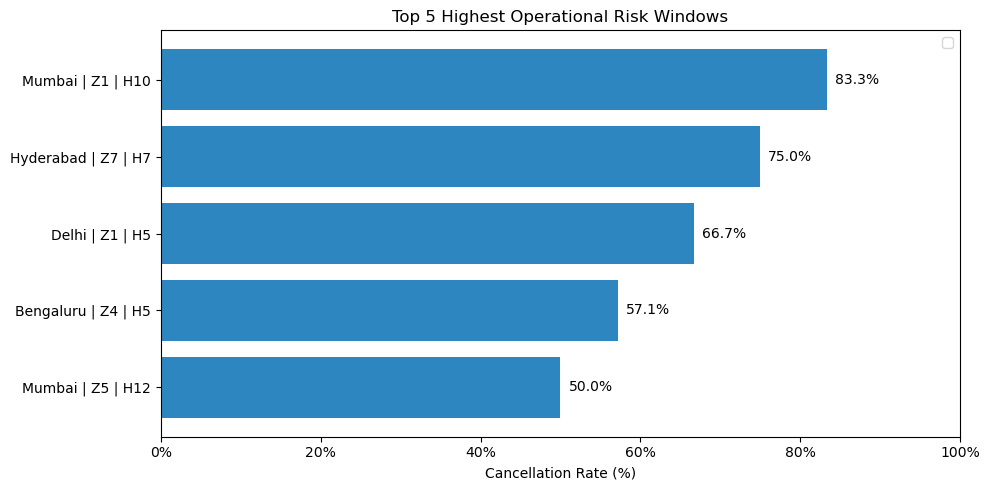

In [102]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Sort top 5 highest risk windows
top5 = stress.sort_values("Cancellation_Rate", ascending=False).head(5)

# Create labels
labels = (
    top5["City"] +
    " | Z" + top5["Pickup_Zone"].astype(str) +
    " | H" + top5["Hour"].astype(str)
)

plt.figure(figsize=(10,5))

bars = plt.barh(labels, top5["Cancellation_Rate"], color="#2E86C1")

# Format X-axis as percentage
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Add value labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01,
             bar.get_y() + bar.get_height()/2,
             f"{width:.1%}",
             va='center')

# Add system average reference line
system_avg = df["Cancellation_Flag"].mean()

plt.xlabel("Cancellation Rate (%)")
plt.title("Top 5 Highest Operational Risk Windows")
plt.xlim(0,1)
plt.gca().invert_yaxis()
plt.legend()

plt.tight_layout()
plt.show()




# Task 2 Cancellation Driver Decomposition Analysis 

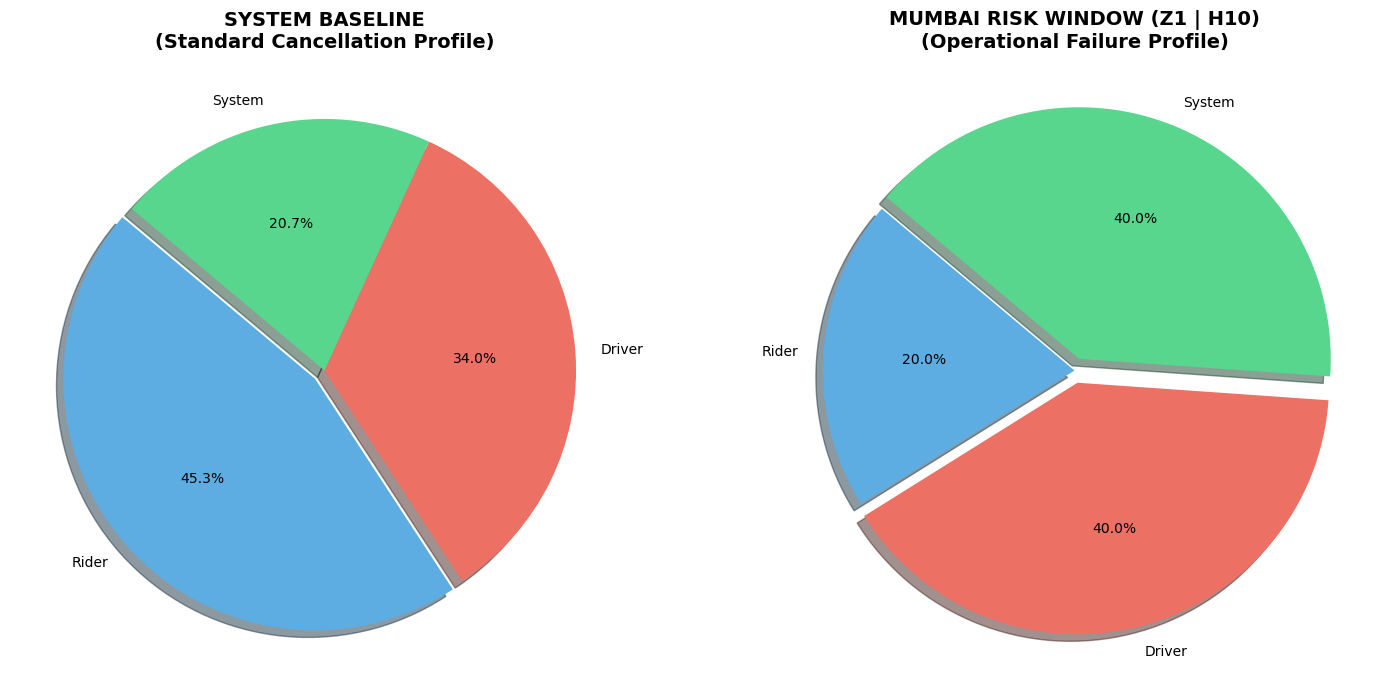

In [103]:
system_cancelled = df[df['Ride_Status'] == 'Cancelled']
system_dist = system_cancelled['Cancellation_By'].value_counts(normalize=True) * 100

mumbai_risk = df[
    (df['City'] == 'Mumbai') & 
    (df['Pickup_Zone'] == 1) & 
    (df['Hour'] == 10) & 
    (df['Ride_Status'] == 'Cancelled')
]
risk_dist = mumbai_risk['Cancellation_By'].value_counts(normalize=True) * 100

categories = ['Rider', 'Driver', 'System']
system_dist = system_dist.reindex(categories).fillna(0)
risk_dist = risk_dist.reindex(categories).fillna(0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))
colors = ['#5dade2', '#ec7063', '#58d68d']

ax1.pie(system_dist, labels=system_dist.index, autopct='%1.1f%%', startangle=140, colors=colors, explode=(0.05, 0, 0), shadow=True)
ax1.set_title('SYSTEM BASELINE\n(Standard Cancellation Profile)', fontsize=14, fontweight='bold')

ax2.pie(risk_dist, labels=risk_dist.index, autopct='%1.1f%%', startangle=140, colors=colors, explode=(0, 0.05, 0.05), shadow=True)
ax2.set_title('MUMBAI RISK WINDOW (Z1 | H10)\n(Operational Failure Profile)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('task2_cancellation_inversion.png')
plt.show()


In [104]:
mumbai_risk_cancelled = df[
    (df['City'] == 'Mumbai') & 
    (df['Pickup_Zone'] == 1) & 
    (df['Hour'] == 10) & 
    (df['Ride_Status'] == 'Cancelled')
]
total_cancelled = len(mumbai_risk_cancelled)
available_count = (mumbai_risk_cancelled['Driver_Available'] == 'Yes').sum()

print(f"Total Cancelled Rides in Mumbai (Z1 | H10): {total_cancelled}")
print(f"Rides with an 'Available' Bike nearby: {available_count}")
print(f"Proof: {(available_count/total_cancelled)*100}% of cancellations had available supply.")

Total Cancelled Rides in Mumbai (Z1 | H10): 5
Rides with an 'Available' Bike nearby: 5
Proof: 100.0% of cancellations had available supply.


In [105]:
df.head(10)

,City,Date,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By,Cancellation_Flag,Completion_Flag,Low_Battery,Peak_Hour
0,Hyderabad,2025-01-01,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0
1,Mumbai,2025-01-01,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,0
2,Delhi,2025-01-01,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled,0,1,0,0
3,Bengaluru,2025-01-01,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System,1,0,1,0
4,Hyderabad,2025-01-01,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,1
5,Hyderabad,2025-01-01,2,4,10,10.39,728.01,1.2,84,Yes,Yes,Rain,Completed,Not_Cancelled,0,1,0,0
6,Hyderabad,2025-01-01,23,5,9,21.20,359.73,1.2,98,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0
7,Hyderabad,2025-01-01,23,4,1,16.54,300.76,2.0,63,No,Yes,Clear,Cancelled,Driver,1,0,0,0
8,Mumbai,2025-01-01,23,4,9,19.09,313.62,2.0,87,No,No,Clear,Cancelled,Rider,1,0,0,0
9,Delhi,2025-01-01,9,8,6,24.72,572.33,1.2,95,Yes,No,Clear,Completed,Not_Cancelled,0,1,0,1


# Task 3: Fleet Utilization Efficiency Assessment

C:\Users\TAMILARASU\AppData\Local\Temp\ipykernel_6708\1392305047.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x='Utilization_%', y='Zone_Label', data=High_demand_Zone, palette='Reds_r')
C:\Users\TAMILARASU\AppData\Local\Temp\ipykernel_6708\1392305047.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='Utilization_%', y='Zone_Label', data=best_source, palette='Greens_r')


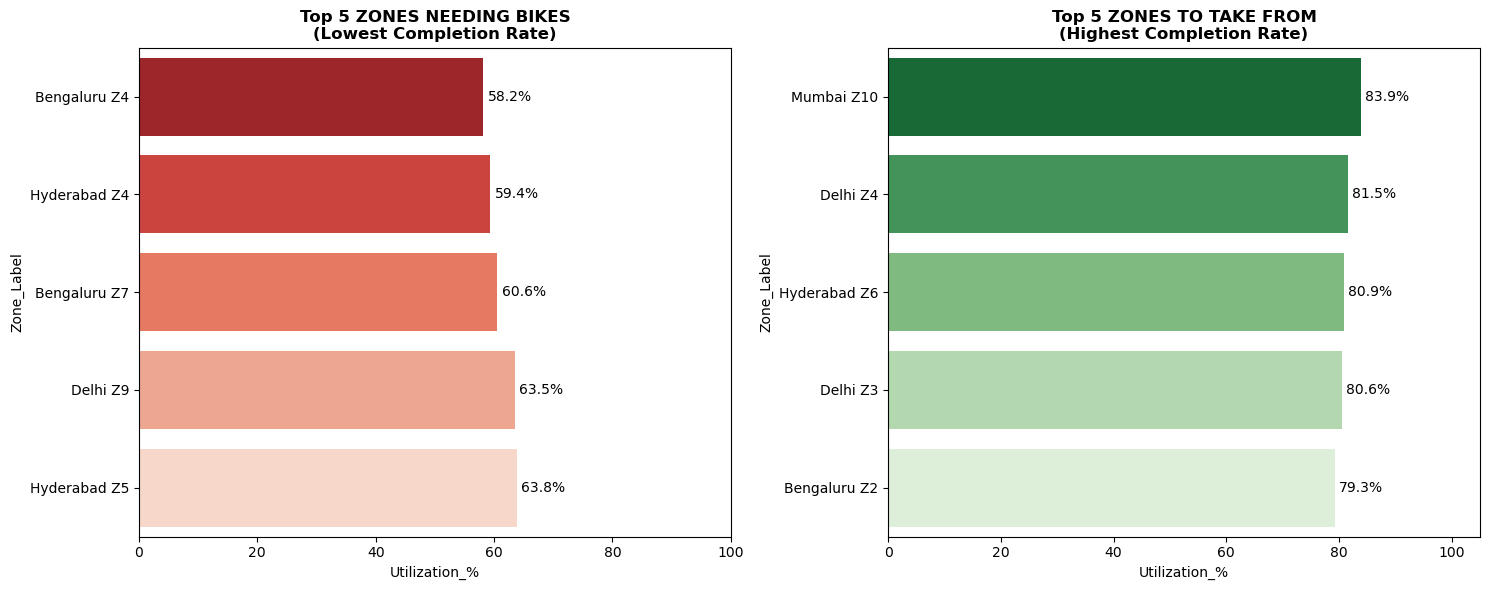

In [106]:
zone_stats = df.groupby(['City', 'Pickup_Zone']).agg(
    Total_Requests=('Ride_Status', 'count'),
    Completed_Rides=('Ride_Status', lambda x: (x == 'Completed').sum())
).reset_index()

zone_stats['Utilization_%'] = (zone_stats['Completed_Rides'] / zone_stats['Total_Requests']) * 100
zone_stats['Zone_Label'] = zone_stats['City'] + ' Z' + zone_stats['Pickup_Zone'].astype(str)

High_demand_Zone = zone_stats.sort_values(by='Utilization_%', ascending=True).head(5)

best_source = zone_stats.sort_values(by='Utilization_%', ascending=False).head(5)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(ax=axes[0], x='Utilization_%', y='Zone_Label', data=High_demand_Zone, palette='Reds_r')
axes[0].set_title('Top 5 ZONES NEEDING BIKES\n(Lowest Completion Rate)', fontsize=12, fontweight='bold')
axes[0].set_xlim(0, 100)
for i in axes[0].containers:
    axes[0].bar_label(i, fmt='%.1f%%', padding=3)

sns.barplot(ax=axes[1], x='Utilization_%', y='Zone_Label', data=best_source, palette='Greens_r')
axes[1].set_title('Top 5 ZONES TO TAKE FROM\n(Highest Completion Rate)', fontsize=12, fontweight='bold')
axes[1].set_xlim(0, 105)
for i in axes[1].containers:
    axes[1].bar_label(i, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.show()

In [107]:
df.head()

,City,Date,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By,Cancellation_Flag,Completion_Flag,Low_Battery,Peak_Hour
0,Hyderabad,2025-01-01,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0
1,Mumbai,2025-01-01,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,0
2,Delhi,2025-01-01,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled,0,1,0,0
3,Bengaluru,2025-01-01,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System,1,0,1,0
4,Hyderabad,2025-01-01,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,1


In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   City                     2500 non-null   object        
 1   Date                     2500 non-null   datetime64[ns]
 2   Hour                     2500 non-null   int64         
 3   Pickup_Zone              2500 non-null   int64         
 4   Drop_Zone                2500 non-null   int64         
 5   Ride_Distance_km         2500 non-null   float64       
 6   Estimated_Fare           2500 non-null   float64       
 7   Surge_Multiplier         2500 non-null   float64       
 8   EV_Battery_%             2500 non-null   int64         
 9   Driver_Available         2500 non-null   object        
 10  Charging_Station_Nearby  2500 non-null   object        
 11  Weather                  2500 non-null   object        
 12  Ride_Status              2500 non-

# Before Procedings to Task 4 We need to add the Day column Next to Date column

In [ ]:
date_pos=df.columns.get_loc('Date')
# insert the day col next to date col
df.insert(date_pos+1,'Day',df['Date'].dt.day_name())

In [ ]:
completed_rides=df[(df["Ride_Status"]=="Completed")]
avg_charge=completed_rides["EV_Battery_%"].mean()
print(avg_charge)

59.42362294151051


# i need to find the threshold level of battery to check for that im using the 1st Quartile

In [132]:
Q1=completed_rides["EV_Battery_%"].quantile(0.25)
print(Q1)

39.0


# The Threshold Level of Battery is 39.0 we will round of and put it as 40

In [147]:
critical_battery=df[(df["EV_Battery_%"]< 40) & (df['Charging_Station_Nearby']=="Yes")]
bottleneck_analysis = critical_battery.groupby(['City','Drop_Zone','Hour']).size().reset_index(name='Bikes_Needing_Charge')
Final_charging_stations = bottleneck_analysis.sort_values(by='Bikes_Needing_Charge', ascending=False)
Final_charging_stations

,City,Drop_Zone,Hour,Bikes_Needing_Charge
336,Mumbai,7,3,4
368,Mumbai,10,13,4
137,Delhi,5,20,3
226,Hyderabad,5,11,3
26,Bengaluru,3,18,3
...,...,...,...,...
136,Delhi,5,18,1
135,Delhi,5,15,1
133,Delhi,5,13,1
131,Delhi,5,11,1


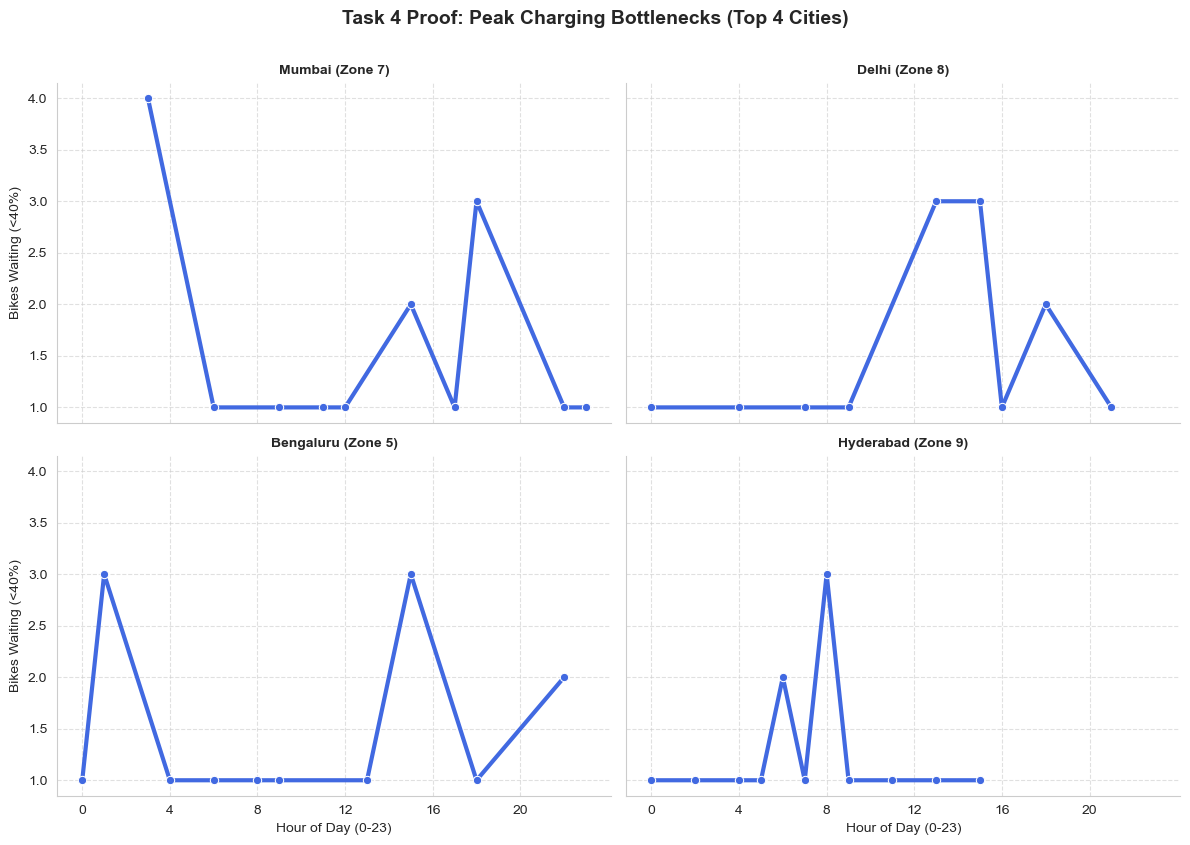

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

Final_charging_stations['Location_Label'] = Final_charging_stations['City'] + " (Zone " + Final_charging_stations['Drop_Zone'].astype(str) + ")"

top_cities = Final_charging_stations.sort_values('Bikes_Needing_Charge', ascending=False).drop_duplicates('City').head(4)
selected_labels = top_cities['Location_Label'].tolist()

plot_data = Final_charging_stations[Final_charging_stations['Location_Label'].isin(selected_labels)]

sns.set_style("whitegrid")

g = sns.relplot(
    data=plot_data,
    x="Hour", 
    y="Bikes_Needing_Charge",
    col="Location_Label",
    col_wrap=2,
    kind="line",
    marker="o",
    linewidth=3,
    height=4, 
    aspect=1.5,
    color="#4169E1"
)

g.fig.suptitle('Task 4 Proof: Peak Charging Bottlenecks (Top 4 Cities)', y=1.05, fontsize=14, fontweight='bold')
g.set_axis_labels("Hour of Day (0-23)", "Bikes Waiting (<40%)")
g.set_titles("{col_name}", fontweight='bold')

for ax in g.axes.flat:
    ax.set_xticks(range(0, 24, 4))
    ax.grid(True, linestyle='--', alpha=0.6)

plt.show()

# Finally Making the New Excel Model i.e Modified Excel File

In [156]:
df.to_excel('modified_voltride_dataset_DecodeX.xlsx',index=False)